In [2]:
!pip install lightkurve -q
import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
D = '/content/drive/MyDrive/Component1'
os.makedirs(f'{D}/app_test', exist_ok=True)
print('ready')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ready


In [3]:
import lightkurve as lk

meta = pd.read_csv(f'{D}/dataset/flare_dataset_split_meta.csv')
print(meta.columns.tolist())
tcol = [c for c in meta.columns if c.lower() in ('tic', 'tic_id', 'star_id')][0]
test_tics = meta.loc[meta['split'] == 'test_lin', tcol].unique()

found = None
for tic in test_tics:
    sr = lk.search_lightcurve(f'TIC {int(tic)}', author='SPOC', exptime=120)
    secs = [int(str(m).split()[-1]) for m in sr.table['mission']]
    late = [s for s in secs if s > 72]
    if late:
        found = (int(tic), late[0], sr[secs.index(late[0])])
        break
tic, sec, item = found
print(f'Using TIC {tic}, sector {sec}')

lc = item.download(quality_bitmask='default').remove_nans()
df = pd.DataFrame({'time': lc.time.value, 'flux': lc.flux.value, 'flux_err': lc.flux_err.value})
path = f'{D}/app_test/TIC{tic}_S{sec}.csv'
df.to_csv(path, index=False)
print(f'Saved {path} ({len(df)} points, {df.time.max() - df.time.min():.1f} days)')

stars = pd.read_csv(f'{D}/catalogues/lin2024_stars.csv')
row = stars[stars.TIC == tic].iloc[0]
print(f'Teff = {row.Teff} K | radius = {row.Rad} R☉ | contamination = {row.Rcont}')

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


['TIC', 'sector', 'source', 'type', 'y_flare', 'y_logE', 'tpeak_btjd', 'peak_index', 'snr', 'height', 'low_snr', 'split']
Using TIC 102306789, sector 101
Saved /content/drive/MyDrive/Component1/app_test/TIC102306789_S101.csv (15642 points, 24.2 days)
Teff = 5550.0 K | radius = 0.931 R☉ | contamination = 0.0059


In [4]:
# ===== 1. the inputs: exactly what a user gives =====
CSV_PATH = f'{D}/app_test/TIC102306789_S101.csv'
TEFF, RADIUS, CONTAM = 5550.0, 0.931, 0.0059

lc = pd.read_csv(CSV_PATH)
assert {'time', 'flux', 'flux_err'} <= set(lc.columns), 'CSV needs time, flux, flux_err'
lc = lc[['time', 'flux', 'flux_err']].dropna().sort_values('time').reset_index(drop=True)
lc = lc[(lc.flux > 0) & (lc.flux_err > 0)].reset_index(drop=True)
print(f'{len(lc)} points | {lc.time.min():.2f} to {lc.time.max():.2f} BTJD | '
      f'cadence {np.median(np.diff(lc.time)) * 1440:.1f} min')

warn = []
if CONTAM > 0.1: warn.append('contamination > 0.1: light from nearby stars may affect results')
if not 3000 <= TEFF <= 7500: warn.append('Teff outside the F/G/K/M training range')
if RADIUS > 2: warn.append('radius > 2 R☉: may be a giant; the model was trained on dwarfs')
print('\n'.join('⚠ ' + w for w in warn) if warn else '✔ inputs OK')

# ===== 2. which normalisation did Step 5 use? =====
data = np.load(f'{D}/dataset/flare_dataset_split.npz', allow_pickle=True)
Xf = data['X_flux']
meta = pd.read_csv(f'{D}/dataset/flare_dataset_split_meta.csv')

rows = []
for i in meta.index[(meta.y_flare == 1) & (meta.split == 'train')][:15]:
    r = meta.loc[i]
    f = pd.read_csv(f'{D}/lightcurves/TIC{int(r.TIC)}_S{int(r.sector):02d}.csv').dropna()
    t, fl = f.time.values, f.flux.values
    j = int(np.argmin(np.abs(t - r.tpeak_btjd)))
    best = None
    for s in range(max(0, j - 130), min(len(fl) - 128, j + 5)):          # find where this window came from
        rr = fl[s:s + 128] / Xf[i]
        sc = np.std(rr) / np.mean(rr)
        if best is None or sc < best[0]:
            best = (sc, s, np.mean(rr))
    sc, s, scale = best
    gaps = np.where(np.diff(t) > 0.5)[0]                                   # orbit = between gaps > 0.5 day
    a = gaps[gaps < s].max() + 1 if (gaps < s).any() else 0
    b = gaps[gaps >= s].min() + 1 if (gaps >= s).any() else len(fl)
    rows.append(dict(window_found=sc < 1e-4,
                     vs_sector_median=scale / np.median(fl),
                     vs_orbit_median=scale / np.median(fl[a:b]),
                     vs_window_median=scale / np.median(fl[s:s + 128])))
chk = pd.DataFrame(rows).round(4)
print(chk.to_string(index=False))
print('\nThe column that is 1.0 in every row = the method Step 5 used')

15642 points | 4101.13 to 4125.29 BTJD | cadence 2.0 min
✔ inputs OK
 window_found  vs_sector_median  vs_orbit_median  vs_window_median
         True            1.0002           1.0002               1.0
         True            1.0002           1.0002               1.0
         True            1.0004           1.0004               1.0
         True            0.9997           0.9997               1.0
         True            1.0061           1.0065               1.0
         True            0.9996           1.0000               1.0
         True            1.0107           1.0111               1.0
         True            1.0027           1.0032               1.0
         True            0.9959           0.9956               1.0
         True            0.9924           0.9921               1.0
         True            0.9866           0.9868               1.0
         True            1.0085           1.0087               1.0
         True            0.9953           0.9951            

In [5]:
from tensorflow import keras

model = keras.models.load_model(f'{D}/model/best_v2.keras')
THR = json.load(open(f'{D}/model/settings_v2.json'))['threshold']
st = json.load(open(f'{D}/dataset/prep_settings.json'))

W, STEP, GAP = 128, 16, 10 / 1440                      # window, step, gap limit (10 min)
t, fx, fe = lc.time.values, lc.flux.values, lc.flux_err.values

# 1. cut windows (skip any that cross a data gap)
all_starts = range(0, len(t) - W + 1, STEP)
starts = np.array([s for s in all_starts if np.diff(t[s:s + W]).max() <= GAP])
idx = starts[:, None] + np.arange(W)                    # point numbers inside each window

# 2. normalise each window by its own median (same as Step 5)
med = np.median(fx[idx], axis=1, keepdims=True)
fl, er = fx[idx] / med, fe[idx] / med
exc = fl - 1

# 3. the 2 channels + scaled star values (same as Step 7)
ch1 = np.clip(exc / np.maximum(er, 1e-6), -10, 60)
ch2 = np.arcsinh(exc / 0.01)
Xw = np.stack([ch1, ch2], axis=-1).astype(np.float32)
s_one = (np.array([TEFF, np.log10(RADIUS)]) - np.array(st['star_mean'])) / np.array(st['star_std'])
Sw = np.tile(s_one.astype(np.float32), (len(starts), 1))

# 4. predict every window
out = model.predict({'light_curve': Xw, 'star': Sw}, batch_size=1024, verbose=0)
pw = out['flare'][:, 0]                                                  # flare probability
Ew = out['energy'][:, 0] * st['logE_std'] + st['logE_mean']              # log10 energy (erg)
flag = pw >= THR

print(f'{len(starts)} windows checked ({len(all_starts) - len(starts)} skipped at data gaps)')
print(f'{flag.sum()} windows above threshold {THR} | highest probability {pw.max():.2f}')

947 windows checked (23 skipped at data gaps)
51 windows above threshold 0.43 | highest probability 0.62


✔ 947 windows checked | star type G | inputs: CSV + Teff 5550.0 K, radius 0.931 R☉, contamination 0.0059
Flares: 28 | low-SNR: 26 | strongest: 1.6e+33 erg (Superflare)
type
Solar-like             0
Large                  1
Superflare            27
Extreme superflare     0

 flare_id  peak_time  flare_prob  peak_brightening_pct  snr  low_snr energy_erg  log10_energy       type
        1  4102.5738        0.54                 0.233  3.9     True    1.4e+33         33.15 Superflare
        2  4102.6377        0.58                 0.194  3.2     True    1.3e+33         33.12 Superflare
        3  4102.7725        0.50                 0.151  2.5     True    1.1e+33         33.04 Superflare
        4  4105.8532        0.46                 0.170  2.8     True    9.6e+32         32.98      Large
        5  4105.9907        0.46                 0.179  3.0     True    1.1e+33         33.03 Superflare
        6  4106.4199        0.53                 0.231  3.8     True    1.4e+33         33.14 Su

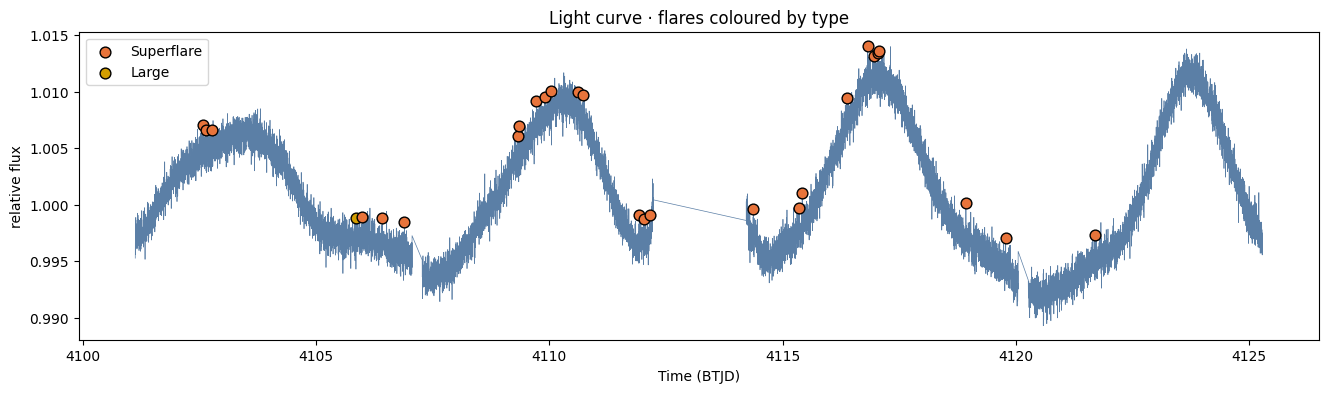

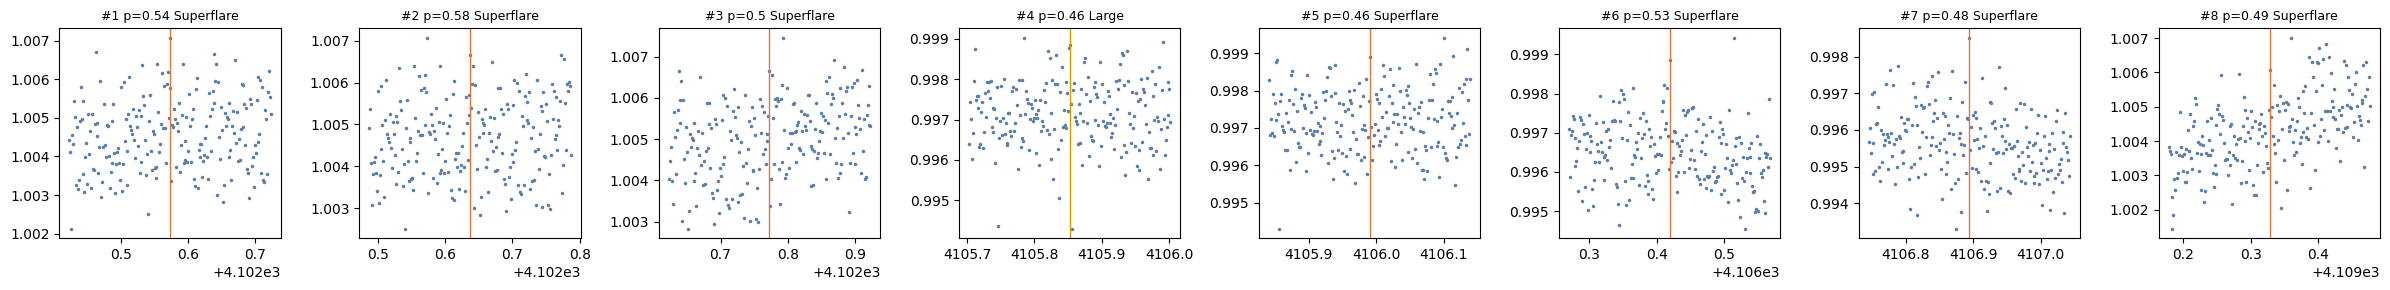

In [6]:
TYPES, CUTS = ['Solar-like', 'Large', 'Superflare', 'Extreme superflare'], [32, 33, 34]
COL = {'Solar-like': '#2e9e5b', 'Large': '#d39e00', 'Superflare': '#e8743b', 'Extreme superflare': '#c62828'}
spt = 'M' if TEFF < 3900 else 'K' if TEFF < 5300 else 'G' if TEFF < 6000 else 'F'

# 1. peak point of every flagged window
pk = pd.DataFrame([(idx[w, j], ch1[w, j], pw[w]) for w in np.where(flag)[0]
                   for j in [int(np.argmax(ch1[w]))]], columns=['i', 'sig', 'p']).sort_values('i')

# 2. join peaks less than 20 min apart into one flare
groups, cur = [], []
for r in pk.itertuples():
    if cur and t[r.i] - t[cur[-1].i] > 20 / 1440:
        groups.append(cur); cur = []
    cur.append(r)
if cur: groups.append(cur)

# 3. measure each flare + energy from the window where its peak sits near 40%
rows = []
for g in groups:
    i0 = max(g, key=lambda r: r.sig).i
    pos = i0 - starts
    cand = np.where((pos >= 0) & (pos < W))[0]
    w = cand[np.argmin(np.abs(pos[cand] - 0.4 * W))]
    e, s_ = exc[w, pos[w]], exc[w, pos[w]] / er[w, pos[w]]
    logE = float(Ew[w])
    rows.append(dict(peak_time=round(t[i0], 4), flare_prob=round(max(r.p for r in g), 2),
                     peak_brightening_pct=round(100 * e, 3), snr=round(s_, 1), low_snr=bool(s_ < 5),
                     energy_erg=f'{10 ** logE:.1e}', log10_energy=round(logE, 2),
                     type=TYPES[np.digitize(logE, CUTS)]))
res = pd.DataFrame(rows)
if len(res): res.insert(0, 'flare_id', range(1, len(res) + 1))

# 4. confirmation bar + summary
print(f'✔ {len(starts)} windows checked | star type {spt} | inputs: CSV + Teff {TEFF} K, '
      f'radius {RADIUS} R☉, contamination {CONTAM}')
if len(res) == 0:
    print('No flares found above the threshold.')
else:
    top = res.loc[res.log10_energy.idxmax()]
    print(f'Flares: {len(res)} | low-SNR: {res.low_snr.sum()} | strongest: {top.energy_erg} erg ({top.type})')
    print(res.type.value_counts().reindex(TYPES, fill_value=0).to_string())
    print(); print(res.to_string(index=False))
    res.to_csv(CSV_PATH.replace('.csv', '_flares.csv'), index=False)

# 5. light curve chart, flares coloured by type
show = fx / np.median(fx)                                   # display only
plt.figure(figsize=(16, 4))
plt.plot(t, show, lw=0.5, color='#5B7FA6')
for r in res.itertuples() if len(res) else []:
    plt.scatter(r.peak_time, show[np.argmin(np.abs(t - r.peak_time))], s=60, color=COL[r.type],
                edgecolor='k', zorder=3, label=r.type)
h, l = plt.gca().get_legend_handles_labels()
if h: plt.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys())
plt.xlabel('Time (BTJD)'); plt.ylabel('relative flux'); plt.title('Light curve · flares coloured by type')
plt.show()

# 6. zoom on each flare (up to 8)
if len(res):
    n = min(len(res), 8)
    fig, axs = plt.subplots(1, n, figsize=(3 * n, 3), squeeze=False)
    for a, r in zip(axs[0], res.head(n).itertuples()):
        m = np.abs(t - r.peak_time) < 0.15
        a.plot(t[m], show[m], '.', ms=3, color='#5B7FA6')
        a.axvline(r.peak_time, color=COL[r.type], lw=1)
        a.set_title(f'#{r.flare_id} p={r.flare_prob} {r.type}', fontsize=9)
    plt.tight_layout(); plt.show()

In [7]:
from tensorflow import keras
model = keras.models.load_model(f'{D}/model/best_v2.keras')
st = json.load(open(f'{D}/dataset/prep_settings.json'))
W, STEP, GAP = 128, 16, 10 / 1440
sm, ss = np.array(st['star_mean']), np.array(st['star_std'])

def run_len(z, j, sig):
    """How many points in a row, around point j, are above sig."""
    if z[j] <= sig: return 0
    a = j
    while a > 0 and z[a - 1] > sig: a -= 1
    b = j
    while b < len(z) - 1 and z[b + 1] > sig: b += 1
    return b - a + 1

def candidates(t, fx, fe, teff, radius, pmin=0.3):
    """The app's pipeline (Steps 4-5) for one light curve. Keeps every candidate with p >= pmin."""
    starts = np.array([s for s in range(0, len(t) - W + 1, STEP) if np.diff(t[s:s + W]).max() <= GAP])
    if len(starts) == 0: return pd.DataFrame()
    idx = starts[:, None] + np.arange(W)
    med = np.median(fx[idx], axis=1, keepdims=True)
    exc, er = fx[idx] / med - 1, fe[idx] / med
    z = exc / np.maximum(er, 1e-6)
    Xw = np.stack([np.clip(z, -10, 60), np.arcsinh(exc / 0.01)], -1).astype(np.float32)
    s1 = ((np.array([teff, np.log10(radius)]) - sm) / ss).astype(np.float32)
    out = model.predict({'light_curve': Xw, 'star': np.tile(s1, (len(starts), 1))}, batch_size=2048, verbose=0)
    pw = out['flare'][:, 0]
    Ew = out['energy'][:, 0] * st['logE_std'] + st['logE_mean']
    pk = [(idx[w, j], z[w, j], pw[w]) for w in np.where(pw >= pmin)[0] for j in [int(np.argmax(z[w]))]]
    if not pk: return pd.DataFrame()
    pk = pd.DataFrame(pk, columns=['i', 'sig', 'p']).sort_values('i')
    groups, cur = [], []
    for r in pk.itertuples():
        if cur and t[r.i] - t[cur[-1].i] > 20 / 1440:
            groups.append(cur); cur = []
        cur.append(r)
    groups.append(cur)
    rows = []
    for g in groups:
        i0 = max(g, key=lambda r: r.sig).i
        pos = i0 - starts
        cand = np.where((pos >= 0) & (pos < W))[0]
        w = cand[np.argmin(np.abs(pos[cand] - 0.4 * W))]; j = pos[w]
        rows.append(dict(peak_time=t[i0], prob=max(r.p for r in g), snr=z[w, j],
                         brightening_pct=100 * exc[w, j], log10_energy=float(Ew[w]),
                         run_25=run_len(z[w], j, 2.5), run_3=run_len(z[w], j, 3.0)))
    return pd.DataFrame(rows)

# quick check on your G star
g = candidates(lc.time.values, lc.flux.values, lc.flux_err.values, TEFF, RADIUS)
print(f'{len(g)} candidates (p ≥ 0.3) | {(g.prob >= 0.43).sum()} with p ≥ 0.43')
print(g[g.prob >= 0.43][['peak_time', 'prob', 'snr', 'run_25', 'run_3']].round(2).head(10).to_string(index=False))

56 candidates (p ≥ 0.3) | 28 with p ≥ 0.43
 peak_time  prob  snr  run_25  run_3
   4102.57  0.54 3.88       1      1
   4102.64  0.58 3.23       1      1
   4102.77  0.50 2.52       1      0
   4105.85  0.46 2.82       2      0
   4105.99  0.46 2.96       1      0
   4106.42  0.53 3.82       1      1
   4106.89  0.48 4.82       1      1
   4109.33  0.49 2.81       1      0
   4109.36  0.52 3.92       1      1
   4109.72  0.48 3.60       1      1


In [8]:
meta = pd.read_csv(f'{D}/dataset/flare_dataset_split_meta.csv')
star = np.load(f'{D}/dataset/flare_dataset_split.npz', allow_pickle=True)['star']
v = meta[meta.split == 'val'].copy()
v['teff'], v['rad'] = star[v.index, 0], star[v.index, 1]
pairs = v.groupby(['TIC', 'sector']).agg(teff=('teff', 'first'), rad=('rad', 'first')).reset_index()
cat = v[v.y_flare == 1]                                    # catalogue flares of the validation stars

all_c, done = [], []
for n, r in enumerate(pairs.itertuples()):
    path_ = f'{D}/lightcurves/TIC{int(r.TIC)}_S{int(r.sector):02d}.csv'
    if not os.path.exists(path_): continue
    f = pd.read_csv(path_).dropna()
    f = f[(f.flux > 0) & (f.flux_err > 0)].sort_values('time')
    c = candidates(f.time.values, f.flux.values, f.flux_err.values, r.teff, r.rad)
    done.append((r.TIC, r.sector))
    if len(c):
        tp = cat[(cat.TIC == r.TIC) & (cat.sector == r.sector)]
        ids = []
        for x in c.peak_time:                              # which catalogue flare it matches (-1 = none)
            d_ = np.abs(tp.tpeak_btjd.values - x) if len(tp) else np.array([])
            ids.append(tp.index[d_.argmin()] if len(d_) and d_.min() < 30 / 1440 else -1)
        c['cat_id'], c['TIC'], c['sector'] = ids, r.TIC, r.sector
        all_c.append(c)
    if n % 25 == 0: print(f'{n}/{len(pairs)} light curves done')

C = pd.concat(all_c, ignore_index=True)
cat_done = cat[pd.MultiIndex.from_frame(cat[['TIC', 'sector']]).isin(done)]
n_lc = len(done)
C.to_csv(f'{D}/app_test/val_candidates.csv', index=False)
print(f'\n{n_lc} validation light curves | {len(cat_done)} catalogue flares | {len(C)} candidates (p ≥ 0.3)')
print(f'candidates matching a catalogue flare: {(C.cat_id >= 0).sum()} | not matching: {(C.cat_id < 0).sum()}')

0/220 light curves done
25/220 light curves done
50/220 light curves done
75/220 light curves done
100/220 light curves done
125/220 light curves done
150/220 light curves done
175/220 light curves done
200/220 light curves done

220 validation light curves | 991 catalogue flares | 9349 candidates (p ≥ 0.3)
candidates matching a catalogue flare: 730 | not matching: 8619


In [9]:
rules = {'no rule':      lambda d: np.ones(len(d), bool),
         '2 pts ≥ 2.5σ': lambda d: d.run_25 >= 2,
         '3 pts ≥ 2.5σ': lambda d: d.run_25 >= 3,
         '2 pts ≥ 3σ':   lambda d: d.run_3 >= 2,
         '3 pts ≥ 3σ':   lambda d: d.run_3 >= 3}
low_ids = set(cat_done.index[cat_done.low_snr.astype(str) == 'True'])

rows = []
for thr in [0.43, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    for name, fn in rules.items():
        k = C[(C.prob >= thr) & fn(C)]
        found = set(k.cat_id[k.cat_id >= 0])
        rows.append(dict(threshold=thr, rule=name,
                         recall=len(found) / len(cat_done),
                         low_snr_recall=len(found & low_ids) / max(len(low_ids), 1),
                         false_alarms_per_sector=(k.cat_id < 0).sum() / n_lc))
tune = pd.DataFrame(rows).round(3)
tune.to_csv(f'{D}/results/app_threshold_tuning.csv', index=False)
print(tune.to_string(index=False))

# choose: most catalogue flares found with ≤ 1 false alarm per sector
ok = tune[tune.false_alarms_per_sector <= 1.0]
best = (ok if len(ok) else tune.sort_values('false_alarms_per_sector')).sort_values(
    ['recall', 'false_alarms_per_sector'], ascending=[False, True]).iloc[0]
print(f'\nChosen: threshold {best.threshold} + {best.rule} | recall {best.recall} | '
      f'low-SNR recall {best.low_snr_recall} | false alarms per sector {best.false_alarms_per_sector}')
json.dump({'threshold': float(best.threshold), 'rule': best.rule, 'tuned_on': 'validation light curves'},
          open(f'{D}/model/app_settings.json', 'w'), indent=2)

 threshold         rule  recall  low_snr_recall  false_alarms_per_sector
      0.43      no rule   0.683           0.379                   20.073
      0.43 2 pts ≥ 2.5σ   0.597           0.237                    5.359
      0.43 3 pts ≥ 2.5σ   0.552           0.184                    3.864
      0.43   2 pts ≥ 3σ   0.561           0.182                    4.364
      0.43   3 pts ≥ 3σ   0.495           0.126                    3.268
      0.50      no rule   0.659           0.333                   13.655
      0.50 2 pts ≥ 2.5σ   0.591           0.228                    4.450
      0.50 3 pts ≥ 2.5σ   0.549           0.179                    3.259
      0.50   2 pts ≥ 3σ   0.558           0.179                    3.695
      0.50   3 pts ≥ 3σ   0.493           0.124                    2.768
      0.60      no rule   0.610           0.246                    6.645
      0.60 2 pts ≥ 2.5σ   0.575           0.202                    3.036
      0.60 3 pts ≥ 2.5σ   0.539           0.163    

In [10]:
CONF, CAND = (0.9, rules['2 pts ≥ 2.5σ']), (0.7, rules['2 pts ≥ 2.5σ'])
json.dump({'confirmed': {'threshold': 0.9, 'rule': '2 pts ≥ 2.5σ'},
           'candidate': {'threshold': 0.7, 'rule': '2 pts ≥ 2.5σ'},
           'tuned_on': 'validation light curves (220)'},
          open(f'{D}/model/app_settings.json', 'w'), indent=2)

g = candidates(lc.time.values, lc.flux.values, lc.flux_err.values, TEFF, RADIUS)
conf = (g.prob >= CONF[0]) & CONF[1](g)
cand = (g.prob >= CAND[0]) & CAND[1](g) & ~conf
print(f'G star (TIC 102306789, sector 101)')
print(f'  before (0.43, no rule): {(g.prob >= 0.43).sum()} flares')
print(f'  after:  {conf.sum()} confirmed | {cand.sum()} candidates')
out_ = g[conf | cand].copy()
if len(out_):
    out_['level'] = np.where(conf[conf | cand], 'confirmed', 'candidate')
    print(out_[['peak_time', 'prob', 'snr', 'run_25', 'log10_energy', 'level']].round(2).to_string(index=False))

G star (TIC 102306789, sector 101)
  before (0.43, no rule): 28 flares
  after:  0 confirmed | 0 candidates


M dwarf TIC 427346731, sector 98 | Teff 3438.0 K | radius 0.609 R☉ | contamination 0.0185
✔ 32 confirmed | 16 candidates | low-SNR: 8
 flare_id  peak_time  prob  brightening_pct        snr  low_snr energy_erg  log10_energy               type     level
        1   3994.092 0.997         0.979000   8.035000    False    9.0e+32        32.953              Large confirmed
        2   3994.993 0.998         1.070000   9.292000    False    6.9e+32        32.840              Large confirmed
        3   3995.512 0.851         0.648000   5.676000    False    4.6e+32        32.665              Large candidate
        4   3997.093 1.000         3.333000  28.844999    False    3.9e+33        33.590         Superflare confirmed
        5   3998.057 0.811         0.464000   4.057000     True    4.1e+32        32.617              Large candidate
        6   3998.244 0.926         0.873000   7.815000    False    6.2e+33        33.790         Superflare confirmed
        7   3998.286 0.978         2.517

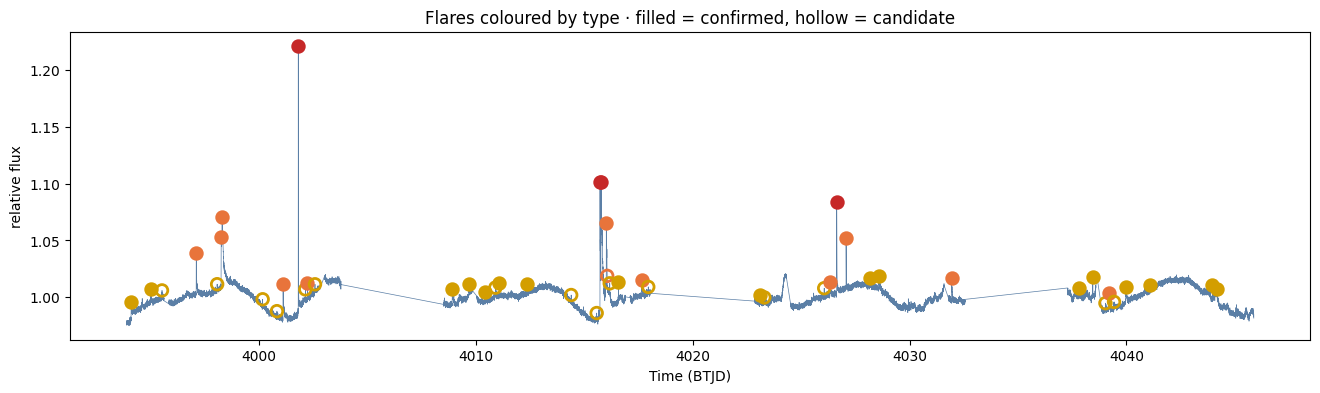

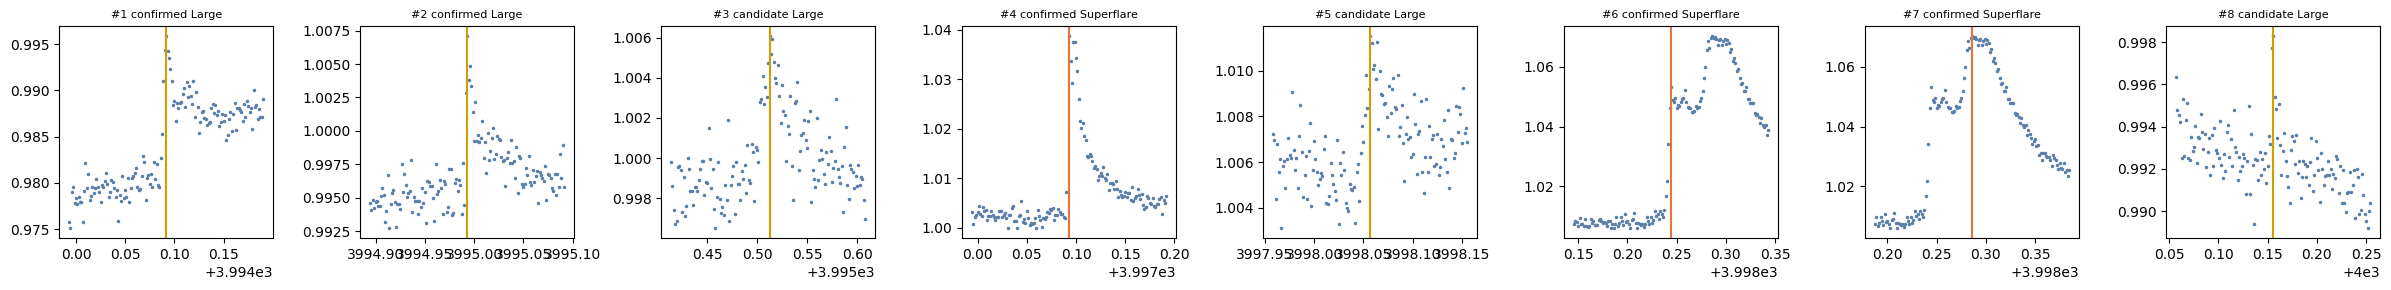

In [12]:
import lightkurve as lk
nf = pd.read_csv(f'{D}/catalogues/lin2024_stars.csv').set_index('TIC').Nf
m_tics = sorted(meta.loc[(meta.split == 'test_lin') & (meta.type == 'M'), 'TIC'].unique(),
                key=lambda t: -nf.get(t, 0))
found = None
for tic in m_tics:
    sr = lk.search_lightcurve(f'TIC {int(tic)}', author='SPOC', exptime=120)
    secs = [int(str(m).split()[-1]) for m in sr.table['mission']]
    late = [s for s in secs if s > 72]
    if late:
        found = (int(tic), late[0], sr[secs.index(late[0])]); break
mtic, msec, item = found
mlc = item.download(quality_bitmask='default').remove_nans()
mdf = pd.DataFrame({'time': mlc.time.value, 'flux': mlc.flux.value, 'flux_err': mlc.flux_err.value})
mdf = mdf[(mdf.flux > 0) & (mdf.flux_err > 0)].sort_values('time').reset_index(drop=True)
mpath = f'{D}/app_test/TIC{mtic}_S{msec}.csv'; mdf.to_csv(mpath, index=False)
row = pd.read_csv(f'{D}/catalogues/lin2024_stars.csv').query('TIC == @mtic').iloc[0]
MTEFF, MRAD, MCON = float(row.Teff), float(row.Rad), float(row.Rcont)
print(f'M dwarf TIC {mtic}, sector {msec} | Teff {MTEFF} K | radius {MRAD} R☉ | contamination {MCON}')

# run the app with both confidence levels
TYPES, CUTS = ['Solar-like', 'Large', 'Superflare', 'Extreme superflare'], [32, 33, 34]
COL = {'Solar-like': '#2e9e5b', 'Large': '#d39e00', 'Superflare': '#e8743b', 'Extreme superflare': '#c62828'}
g = candidates(mdf.time.values, mdf.flux.values, mdf.flux_err.values, MTEFF, MRAD)
conf = (g.prob >= 0.9) & (g.run_25 >= 2)
cand = (g.prob >= 0.7) & (g.run_25 >= 2) & ~conf
res = g[conf | cand].copy()
res['level'] = np.where(conf[conf | cand], 'confirmed', 'candidate')
res['type'] = [TYPES[np.digitize(e, CUTS)] for e in res.log10_energy]
res['energy_erg'] = [f'{10 ** e:.1e}' for e in res.log10_energy]
res['low_snr'] = res.snr < 5
res = res.reset_index(drop=True); res.insert(0, 'flare_id', range(1, len(res) + 1))
print(f'✔ {conf.sum()} confirmed | {cand.sum()} candidates | low-SNR: {res.low_snr.sum()}')
print(res[['flare_id', 'peak_time', 'prob', 'brightening_pct', 'snr', 'low_snr', 'energy_erg',
           'log10_energy', 'type', 'level']].round(3).to_string(index=False))
res.to_csv(mpath.replace('.csv', '_flares.csv'), index=False)

# chart: confirmed = filled circle, candidate = hollow circle
mt, mf = mdf.time.values, mdf.flux.values / np.median(mdf.flux.values)
plt.figure(figsize=(16, 4)); plt.plot(mt, mf, lw=0.5, color='#5B7FA6')
for r in res.itertuples():
    y = mf[np.argmin(np.abs(mt - r.peak_time))]
    plt.scatter(r.peak_time, y, s=70, edgecolor=COL[r.type], linewidth=2,
                color=COL[r.type] if r.level == 'confirmed' else 'none', zorder=3)
plt.xlabel('Time (BTJD)'); plt.ylabel('relative flux')
plt.title('Flares coloured by type · filled = confirmed, hollow = candidate'); plt.show()

n = min(len(res), 8)
if n:
    fig, axs = plt.subplots(1, n, figsize=(3 * n, 3), squeeze=False)
    for a, r in zip(axs[0], res.head(n).itertuples()):
        m = np.abs(mt - r.peak_time) < 0.1
        a.plot(mt[m], mf[m], '.', ms=3, color='#5B7FA6'); a.axvline(r.peak_time, color=COL[r.type])
        a.set_title(f'#{r.flare_id} {r.level} {r.type}', fontsize=8)
    plt.tight_layout(); plt.show()

In [13]:
def merge_complex(res, t, fx, fe, max_gap_h=3):
    """Join detections that are one complex flare (flux stays above normal between the peaks)."""
    if len(res) < 2:
        return res.assign(n_peaks=1, complex=False)
    base = pd.Series(fx).rolling(361, center=True, min_periods=50).median().values   # normal brightness (12 h)
    z = (fx / base - 1) / (fe / base)                                                # how many σ above normal
    z = pd.Series(z).rolling(3, center=True, min_periods=1).mean().values            # smooth noise a little
    res = res.sort_values('peak_time').reset_index(drop=True)
    groups = [[0]]
    for k in range(1, len(res)):
        a, b = res.peak_time[groups[-1][-1]], res.peak_time[k]
        between = (t > a) & (t < b)
        same = (b - a) * 24 <= max_gap_h and between.any() and z[between].min() > 1
        groups[-1].append(k) if same else groups.append([k])
    rows = []
    for g in groups:
        sub = res.loc[g]
        main = sub.loc[sub.brightening_pct.idxmax()].copy()     # brighter peak (its window covers the whole flare)
        main['prob'] = sub.prob.max()
        main['level'] = 'confirmed' if (sub.level == 'confirmed').any() else 'candidate'
        main['n_peaks'], main['complex'] = len(g), len(g) > 1
        rows.append(main)
    out = pd.DataFrame(rows).reset_index(drop=True)
    out['flare_id'] = range(1, len(out) + 1)
    return out

res2 = merge_complex(res, mdf.time.values, mdf.flux.values, mdf.flux_err.values)
print(f'before: {len(res)} flares → after: {len(res2)} flares | complex flares: {res2.complex.sum()}')
print('\nComplex flares (joined):')
print(res2[res2.complex][['flare_id', 'peak_time', 'n_peaks', 'brightening_pct', 'energy_erg',
                          'type', 'level']].round(3).to_string(index=False))
print('\n' + res2.level.value_counts().to_string())
print('\n' + res2.type.value_counts().to_string())
res2.to_csv(mpath.replace('.csv', '_flares.csv'), index=False)

before: 48 flares → after: 45 flares | complex flares: 3

Complex flares (joined):
 flare_id  peak_time  n_peaks  brightening_pct energy_erg               type     level
        6   3998.286        2            2.517    5.8e+33         Superflare confirmed
       22   4015.719        2            6.731    1.1e+34 Extreme superflare confirmed
       23   4016.017        2            5.491    9.1e+33         Superflare confirmed

level
confirmed    30
candidate    15

type
Large                 32
Superflare            10
Extreme superflare     3
